# 15. Multibody dynamics with `sympy.physics.mechanics`

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/15_multibody_mechanics.ipynb)

Notebook 12 derived equations of motion by writing each position in Cartesian coordinates and
differentiating. That works for two pendulums. It becomes painful when bodies rotate relative
to one another, have rotational inertia, or are pushed by applied forces.

`sympy.physics.mechanics` supplies the vocabulary of a dynamics course as objects:

| Object | Meaning |
| --- | --- |
| `ReferenceFrame` | a set of axes, possibly rotating |
| `Point` | a location with a velocity in some frame |
| `Particle`, `RigidBody` | things with mass and inertia |
| `LagrangesMethod`, `KanesMethod` | two ways of turning those into equations of motion |

**Worked examples:** acceleration in polar coordinates, a pendulum, an inverted pendulum on a
cart derived by two methods, its linearization, a controller that balances it, and a rigid rod.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import sympy.physics.mechanics as me
from scipy.integrate import solve_ivp
from scipy.linalg import solve_continuous_are

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

t = me.dynamicsymbols._t          # the time symbol used by the package

## 15.1 Reference frames: where Coriolis and centripetal terms come from

`dynamicsymbols` creates functions of time. A frame `A` is obtained from the fixed frame `N` by
rotating through the angle $\theta(t)$ about the common $z$ axis, so `A.x` is the radial unit
vector and `A.y` the tangential one.

**Problem.** Find the acceleration of a point at $r(t)\,\mathbf{e}_r$ in polar coordinates.

**By hand** you differentiate twice, remembering that the unit vectors rotate:
$\dot{\mathbf e}_r = \dot\theta\,\mathbf e_\theta$ and $\dot{\mathbf e}_\theta = -\dot\theta\,\mathbf e_r$.
The frame object remembers this for you.

In [2]:
r, theta = me.dynamicsymbols("r theta")

N = me.ReferenceFrame("N")                               # fixed (inertial) frame
A = N.orientnew("A", "Axis", [theta, N.z])               # rotates with the point

position = r * A.x
velocity = position.dt(N)                                # time derivative as seen from N
acceleration = velocity.dt(N)
velocity

d                   d           
──(r(t)) a_x + r(t)⋅──(θ(t)) a_y
dt                  dt          

In [3]:
a_radial = sp.simplify(acceleration.dot(A.x))
a_tangential = sp.simplify(acceleration.dot(A.y))
a_radial, a_tangential

⎛                 2    2               2                             ⎞
⎜       ⎛d       ⎞    d               d             d        d       ⎟
⎜- r(t)⋅⎜──(θ(t))⎟  + ───(r(t)), r(t)⋅───(θ(t)) + 2⋅──(r(t))⋅──(θ(t))⎟
⎜       ⎝dt      ⎠      2               2           dt       dt      ⎟
⎝                     dt              dt                             ⎠

$a_r = \ddot r - r\dot\theta^2$ contains the centripetal term, and
$a_\theta = r\ddot\theta + 2\dot r\dot\theta$ contains the Coriolis term. **Verify** against the
textbook formulas.

In [4]:
r_dot, theta_dot = r.diff(t), theta.diff(t)
assert sp.simplify(a_radial - (r.diff(t, 2) - r * theta_dot**2)) == 0
assert sp.simplify(a_tangential - (r * theta.diff(t, 2) + 2 * r_dot * theta_dot)) == 0

## 15.2 Points, particles and Lagrange's method: the pendulum again

The recipe has five steps: frames, points, velocities, bodies with their potential energy, and
the method. For a pendulum of length $l$, let frame `B` swing with the rod so that the bob is at
$-l\,\mathbf{b}_y$.

In [5]:
m, l, g = sp.symbols("m l g", positive=True)
q = me.dynamicsymbols("q")                               # the swing angle

B = N.orientnew("B", "Axis", [q, N.z])                   # 1. frame fixed to the rod
pivot = me.Point("O")
pivot.set_vel(N, 0)                                      # 2. the pivot does not move
bob_point = pivot.locatenew("P", -l * B.y)
bob_point.v2pt_theory(pivot, N, B)                       # 3. velocity of a point fixed on a rotating body

bob = me.Particle("bob", bob_point, m)                   # 4. the body and its potential energy
bob.potential_energy = m * g * bob_point.pos_from(pivot).dot(N.y)

lagrangian = me.Lagrangian(N, bob)                       # 5. T - V, then Lagrange's equations
pendulum = me.LagrangesMethod(lagrangian, [q])
sp.simplify(pendulum.form_lagranges_equations())

⎡    ⎛                 2       ⎞⎤
⎢    ⎜                d        ⎟⎥
⎢l⋅m⋅⎜g⋅sin(q(t)) + l⋅───(q(t))⎟⎥
⎢    ⎜                  2      ⎟⎥
⎣    ⎝                dt       ⎠⎦

In [6]:
# verify: the familiar  q'' = -(g/l) sin q, as in notebook 12
q_ddot = sp.solve(pendulum.form_lagranges_equations()[0], q.diff(t, 2))[0]
assert sp.simplify(q_ddot + g * sp.sin(q) / l) == 0

More typing than notebook 12 for a single pendulum. The investment pays off below, where the
same five steps handle a moving base and an applied force without any new ideas.

## 15.3 An inverted pendulum on a cart

**Problem.** A cart of mass $M$ rolls on a horizontal track at position $x(t)$, pushed by a
force $F(t)$. A light rod of length $l$ with a mass $m$ at its tip is hinged to the cart, and
$\theta(t)$ is its angle from the upward vertical. This is the standard model for balancing
problems: a rocket on its thrust, a two-wheeled scooter, a person standing.

In [7]:
M = sp.symbols("M", positive=True)
x, theta = me.dynamicsymbols("x theta")
F = me.dynamicsymbols("F")

rod = N.orientnew("R", "Axis", [-theta, N.z])            # leaning to the right is positive θ
origin = me.Point("O")
origin.set_vel(N, 0)

cart_point = origin.locatenew("C", x * N.x)
cart_point.set_vel(N, x.diff(t) * N.x)
tip = cart_point.locatenew("T", l * rod.y)
tip.v2pt_theory(cart_point, N, rod)

cart = me.Particle("cart", cart_point, M)
mass = me.Particle("mass", tip, m)
cart.potential_energy = 0
mass.potential_energy = m * g * tip.pos_from(origin).dot(N.y)

cart_pendulum = me.LagrangesMethod(
    me.Lagrangian(N, cart, mass), [x, theta],
    forcelist=[(cart_point, F * N.x)], frame=N,          # the push acts on the cart, along the track
)
equations = sp.simplify(cart_pendulum.form_lagranges_equations())
equations

⎡   2            ⎛                        2                2           2       ↪
⎢  d             ⎜              ⎛d       ⎞                d           d        ↪
⎢M⋅───(x(t)) + m⋅⎜- l⋅sin(θ(t))⋅⎜──(θ(t))⎟  + l⋅cos(θ(t))⋅───(θ(t)) + ───(x(t) ↪
⎢    2           ⎜              ⎝dt      ⎠                  2           2      ↪
⎢  dt            ⎝                                        dt          dt       ↪
⎢                                                                              ↪
⎢                    ⎛                  2                     2       ⎞        ↪
⎢                    ⎜                 d                     d        ⎟        ↪
⎢                l⋅m⋅⎜-g⋅sin(θ(t)) + l⋅───(θ(t)) + cos(θ(t))⋅───(x(t))⎟        ↪
⎢                    ⎜                   2                     2      ⎟        ↪
⎣                    ⎝                 dt                    dt       ⎠        ↪

↪  ⎞       ⎤
↪  ⎟       ⎥
↪ )⎟ - F(t)⎥
↪  ⎟       ⎥
↪  ⎠       ⎥
↪          ⎥
↪          ⎥
↪          ⎥
↪   

**Verify** against the equations found in control textbooks:

$$(M+m)\ddot x + ml\left(\ddot\theta\cos\theta - \dot\theta^2\sin\theta\right) = F,
\qquad l\ddot\theta + \ddot x\cos\theta - g\sin\theta = 0 .$$

In [8]:
x_dd, th_dd, th_d = x.diff(t, 2), theta.diff(t, 2), theta.diff(t)
textbook = sp.Matrix([
    (M + m) * x_dd + m * l * (th_dd * sp.cos(theta) - th_d**2 * sp.sin(theta)) - F,
    m * l * (l * th_dd + x_dd * sp.cos(theta) - g * sp.sin(theta)),
])
assert sp.simplify(equations - textbook) == sp.zeros(2, 1)

`rhs()` solves for the accelerations and returns the first-order system
$\dot{\mathbf{y}} = \mathbf{f}(\mathbf{y}, F)$ with $\mathbf{y} = (x, \theta, \dot x, \dot\theta)$,
ready for `lambdify`.

In [9]:
state_rates = sp.simplify(cart_pendulum.rhs())
state_rates

⎡                             d                                    ⎤
⎢                             ──(x(t))                             ⎥
⎢                             dt                                   ⎥
⎢                                                                  ⎥
⎢                             d                                    ⎥
⎢                             ──(θ(t))                             ⎥
⎢                             dt                                   ⎥
⎢                                                                  ⎥
⎢                                                   2              ⎥
⎢         g⋅m⋅sin(2⋅θ(t))                 ⎛d       ⎞               ⎥
⎢       - ─────────────── + l⋅m⋅sin(θ(t))⋅⎜──(θ(t))⎟  + F(t)       ⎥
⎢                2                        ⎝dt      ⎠               ⎥
⎢       ────────────────────────────────────────────────────       ⎥
⎢                                  2                               ⎥
⎢                         M + m⋅si

## 15.4 The same system by Kane's method

Lagrange's method works from energies. Kane's method works from velocities and forces: you
choose **generalized speeds** $u_i$ (here simply $u_1 = \dot x$, $u_2 = \dot\theta$), list the
bodies and the forces on them, including gravity, and it projects Newton's law onto the
directions in which the system can move. It scales better to large mechanisms and handles
rolling and other velocity constraints, which is why SymPy's own multibody tools are built on it.

In [10]:
u1, u2 = me.dynamicsymbols("u_1 u_2")

rod_k = N.orientnew("R_k", "Axis", [-theta, N.z])
rod_k.set_ang_vel(N, -u2 * N.z)                           # velocities are written with the speeds
cart_k = origin.locatenew("C_k", x * N.x)
cart_k.set_vel(N, u1 * N.x)
tip_k = cart_k.locatenew("T_k", l * rod_k.y)
tip_k.v2pt_theory(cart_k, N, rod_k)

bodies = [me.Particle("cart_k", cart_k, M), me.Particle("mass_k", tip_k, m)]
loads = [(cart_k, F * N.x), (tip_k, -m * g * N.y)]        # push on the cart, weight of the tip mass

kane = me.KanesMethod(N, q_ind=[x, theta], u_ind=[u1, u2], kd_eqs=[x.diff(t) - u1, theta.diff(t) - u2])
kane.kanes_equations(bodies, loads)
kane_rates = sp.simplify(kane.rhs())
kane_rates

⎡                            u₁(t)                            ⎤
⎢                                                             ⎥
⎢                            u₂(t)                            ⎥
⎢                                                             ⎥
⎢         g⋅m⋅sin(2⋅θ(t))         2                           ⎥
⎢       - ─────────────── + l⋅m⋅u₂ (t)⋅sin(θ(t)) + F(t)       ⎥
⎢                2                                            ⎥
⎢       ───────────────────────────────────────────────       ⎥
⎢                               2                             ⎥
⎢                      M + m⋅sin (θ(t))                       ⎥
⎢                                                             ⎥
⎢                      ⎛      2                    ⎞          ⎥
⎢g⋅(M + m)⋅sin(θ(t)) - ⎝l⋅m⋅u₂ (t)⋅sin(θ(t)) + F(t)⎠⋅cos(θ(t))⎥
⎢─────────────────────────────────────────────────────────────⎥
⎢                      ⎛         2      ⎞                     ⎥
⎣                    l⋅⎝M + m⋅sin (θ(t))

In [11]:
# verify: two different formulations, identical equations of motion
same = sp.simplify(kane_rates.subs({u1: x.diff(t), u2: theta.diff(t)}) - state_rates)
assert same == sp.zeros(4, 1)

## 15.5 Linearization about the upright position

The package can linearize its own equations (notebook 9 did this by hand with a Jacobian).
The result is the state-space model $\dot{\mathbf{y}} = \mathbf{A}\mathbf{y} + \mathbf{B}F$
used throughout control engineering.

In [12]:
upright = {x: 0, theta: 0, x.diff(t): 0, theta.diff(t): 0, F: 0}
linearizer = cart_pendulum.to_linearizer(q_ind=[x, theta], qd_ind=[x.diff(t), theta.diff(t)])
A_sym, B_sym = linearizer.linearize(A_and_B=True, op_point=upright)
A_sym, B_sym = sp.simplify(A_sym), sp.simplify(B_sym)
A_sym, B_sym

⎛⎡0      0      1  0⎤  ⎡ 0 ⎤⎞
⎜⎢                  ⎥  ⎢   ⎥⎟
⎜⎢0      0      0  1⎥  ⎢ 0 ⎥⎟
⎜⎢                  ⎥  ⎢   ⎥⎟
⎜⎢     -g⋅m         ⎥  ⎢ 1 ⎥⎟
⎜⎢0    ─────    0  0⎥, ⎢ ─ ⎥⎟
⎜⎢       M          ⎥  ⎢ M ⎥⎟
⎜⎢                  ⎥  ⎢   ⎥⎟
⎜⎢   g⋅(M + m)      ⎥  ⎢-1 ⎥⎟
⎜⎢0  ─────────  0  0⎥  ⎢───⎥⎟
⎝⎣      M⋅l         ⎦  ⎣M⋅l⎦⎠

In [13]:
eigenvalues = A_sym.eigenvals()
eigenvalues

⎧            _______           _______   ⎫
⎪      -√g⋅╲╱ M + m       √g⋅╲╱ M + m    ⎪
⎨0: 2, ──────────────: 1, ────────────: 1⎬
⎪          √M⋅√l             √M⋅√l       ⎪
⎩                                        ⎭

One eigenvalue, $+\sqrt{(M+m)g/(Ml)}$, is positive: the upright position is unstable, as
everyone who has balanced a broom on a hand knows. A longer rod gives a smaller eigenvalue, so
it falls more slowly and is easier to balance.

Can a force on the cart alone stabilize it? Yes, if the system is **controllable**: the matrix
$[\mathbf{B},\ \mathbf{AB},\ \mathbf{A}^2\mathbf{B},\ \mathbf{A}^3\mathbf{B}]$ must have full rank.

In [14]:
controllability = sp.Matrix.hstack(*[A_sym**k * B_sym for k in range(4)])
assert any(sp.simplify(ev).is_positive for ev in eigenvalues) and controllability.rank() == 4
controllability.rank()

4

## 15.6 Balancing it

Use state feedback, $F = -\mathbf{K}\mathbf{y}$, with the gain $\mathbf{K}$ from the
linear-quadratic regulator (LQR), which trades off deviations of the state against control
effort. SciPy solves the Riccati equation; the model matrices come from SymPy.

The controller is designed on the **linear** model and tested on the **nonlinear** one.

In [15]:
numbers = {M: 1.0, m: 0.2, l: 0.5, g: 9.81}                 # kg, kg, m, m/s²
A_num = np.array(A_sym.subs(numbers), dtype=float)
B_num = np.array(B_sym.subs(numbers), dtype=float)

Q_weight = np.diag([1.0, 10.0, 0.0, 0.0])                   # penalize cart drift and, more, the lean angle
R_weight = np.array([[0.1]])                                # penalize force
P = solve_continuous_are(A_num, B_num, Q_weight, R_weight)
K = np.linalg.solve(R_weight, B_num.T @ P)

closed_loop_poles = np.linalg.eigvals(A_num - B_num @ K)
assert np.all(closed_loop_poles.real < 0)                   # every mode now decays
print("gain K =", np.round(K, 2))
print("closed-loop eigenvalues:", np.round(closed_loop_poles, 2))

gain K = [[ -3.16 -40.5   -4.3   -8.39]]
closed-loop eigenvalues: [-5.21+1.92j -5.21-1.92j -1.03+0.98j -1.03-0.98j]


In [16]:
state_symbols = sp.symbols("x_s theta_s v_s omega_s")
F_symbol = sp.symbols("F_s")
to_symbols = {x.diff(t): state_symbols[2], theta.diff(t): state_symbols[3],
              x: state_symbols[0], theta: state_symbols[1], F: F_symbol}       # derivatives first
rates = sp.lambdify((*state_symbols, F_symbol), list(state_rates.subs(to_symbols).subs(numbers)), "numpy")

def simulate(initial_tilt_deg, controlled, t_end=5.0):
    force = (lambda y: float(-(K @ y)[0])) if controlled else (lambda y: 0.0)
    start = [0.0, np.radians(initial_tilt_deg), 0.0, 0.0]
    times = np.linspace(0, t_end, 1001)
    sol = solve_ivp(lambda _, y: rates(*y, force(y)), [0, t_end], start, t_eval=times, rtol=1e-9, atol=1e-9)
    return sol.t, sol.y, np.array([force(y) for y in sol.y.T])

time_c, y_c, force_c = simulate(15, controlled=True)
time_f, y_f, _ = simulate(15, controlled=False, t_end=0.6)

assert abs(y_c[1, -1]) < 1e-3 and abs(y_c[0, -1]) < 1e-2          # balanced, and back at the start
assert np.degrees(abs(y_f[1, -1])) > 60                           # without control it falls over

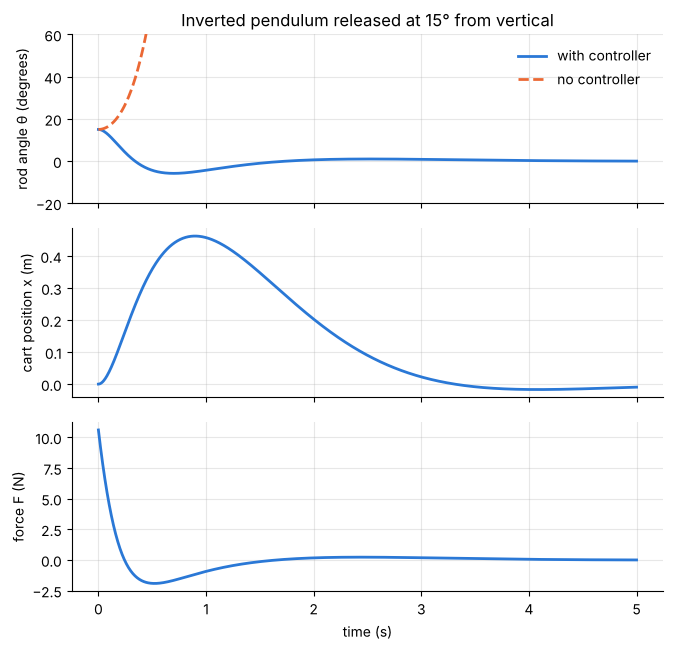

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(6.8, 6.6), sharex=True)
axes[0].plot(time_c, np.degrees(y_c[1]), label="with controller")
axes[0].plot(time_f, np.degrees(y_f[1]), ls="--", label="no controller")
axes[0].set(ylabel="rod angle θ (degrees)", ylim=(-20, 60), title="Inverted pendulum released at 15° from vertical")
axes[0].legend(frameon=False, loc="upper right")
axes[1].plot(time_c, y_c[0])
axes[1].set(ylabel="cart position x (m)")
axes[2].plot(time_c, force_c)
axes[2].set(ylabel="force F (N)", xlabel="time (s)")
fig.tight_layout()

Read the three panels together. The controller first pushes the cart hard to the **right**,
towards the side the rod is leaning, to get the base back under the mass. The cart travels
almost half a metre and is then brought back slowly to its starting point. Without the
controller the rod is past 60° in about half a second.

**Verify the model itself.** With no force and no friction the total energy of the falling
pendulum must be conserved. The package provides the energies.

In [18]:
total_energy = (me.kinetic_energy(N, cart, mass) + me.potential_energy(cart, mass)).subs(to_symbols).subs(numbers)
energy = sp.lambdify(state_symbols, total_energy, "numpy")(*y_f)
print(f"energy drift during the uncontrolled fall: {np.abs(energy - energy[0]).max():.1e} J")
assert np.abs(energy - energy[0]).max() < 1e-6

energy drift during the uncontrolled fall: 1.6e-08 J


## 15.7 Rigid bodies: a swinging rod

A real rod has its mass spread along its length. `RigidBody` needs the frame, the centre of
mass and the inertia about it.

**Problem.** A uniform rod of mass $m$ and length $L$ swings about one end. Find its equation
of motion and the period of small swings.

**By hand.** The moment of inertia about the centre is $mL^2/12$, and about the end
$mL^2/3$ (parallel-axis theorem), so $\tfrac13 mL^2\ddot\phi = -mg\tfrac{L}{2}\sin\phi$.

In [19]:
L = sp.symbols("L", positive=True)
phi = me.dynamicsymbols("phi")

body_frame = N.orientnew("S", "Axis", [phi, N.z])
hinge = me.Point("H")
hinge.set_vel(N, 0)
centre = hinge.locatenew("G", -L / 2 * body_frame.y)
centre.v2pt_theory(hinge, N, body_frame)

central_inertia = me.inertia(body_frame, 0, 0, m * L**2 / 12)        # only rotation about z matters
rod_body = me.RigidBody("rod", centre, body_frame, m, (central_inertia, centre))
rod_body.potential_energy = m * g * centre.pos_from(hinge).dot(N.y)

sp.simplify(me.kinetic_energy(N, rod_body))            # translation of the centre + rotation about it

               2
 2   ⎛d       ⎞ 
L ⋅m⋅⎜──(φ(t))⎟ 
     ⎝dt      ⎠ 
────────────────
       6        

In [20]:
rod_equation = me.LagrangesMethod(me.Lagrangian(N, rod_body), [phi]).form_lagranges_equations()[0]
phi_ddot = sp.solve(rod_equation, phi.diff(t, 2))[0]
assert sp.simplify(phi_ddot + 3 * g * sp.sin(phi) / (2 * L)) == 0
phi_ddot

-3⋅g⋅sin(φ(t)) 
───────────────
      2⋅L      

The kinetic energy came out as $\tfrac16 mL^2\dot\phi^2 = \tfrac12\left(\tfrac13 mL^2\right)\dot\phi^2$:
the package applied the parallel-axis theorem without being told. For small swings
$\ddot\phi = -\dfrac{3g}{2L}\phi$, so the period is $2\pi\sqrt{2L/(3g)}$. The rod swings like a
point-mass pendulum of length $\tfrac23 L$.

In [21]:
period_rod = 2 * sp.pi * sp.sqrt(2 * L / (3 * g))
period_point = 2 * sp.pi * sp.sqrt(L / g)
ratio = sp.simplify(period_rod / period_point)
assert ratio == sp.sqrt(6) / 3
ratio, float(period_rod.subs({L: 1, g: 9.81}))          # a 1 m rod: about 1.64 s

⎛√6                   ⎞
⎜──, 1.637946585913276⎟
⎝3                    ⎠

## Which approach when?

| Situation | Approach |
| --- | --- |
| one or two point masses, a course exercise | positions → energies → `euler_equations` (notebook 12) |
| rotating frames, rigid bodies, applied forces | `LagrangesMethod` with frames and points (15.2, 15.3, 15.7) |
| many bodies, rolling or other velocity constraints | `KanesMethod` (15.4) |
| a controller or a stability study | `linearize` to get $\mathbf{A}$ and $\mathbf{B}$ (15.5) |

The package also has a higher-level interface with bodies, joints and actuators
(`System`, `PinJoint`, `PrismaticJoint`, …) for assembling mechanisms the way a CAD tool does.
Its [documentation](https://docs.sympy.org/latest/modules/physics/mechanics/index.html) has
worked examples up to a full bicycle model.

## Exercises

1. A bead slides on a straight wire that rotates in a horizontal plane at constant angular
   velocity $\Omega$. Using a rotating frame as in 15.1, show that its radial equation of motion
   is $\ddot r = \Omega^2 r$, and find the sideways force the wire must exert on a bead of mass $m$.
2. Derive the double pendulum of notebook 12 with `LagrangesMethod`, using one frame per rod,
   and check that the angular accelerations agree with those of notebook 12 for equal masses
   and lengths at one numerical state.
3. Add viscous friction $-b\dot x$ on the cart and $-c\dot\theta$ at the hinge in 15.3 (as a
   force and a torque in `forcelist`). How do the entries of $\mathbf{A}$ change, and is the
   upright position still unstable?
4. A uniform rod of length $L$ is pivoted at a distance $d$ from its centre. Find the period of
   small swings as a function of $d$, and the value of $d$ that makes it shortest.
   (Answer: $d = L/\sqrt{12}$.)
5. With the controller of 15.6, find by simulation the largest initial tilt from which the
   pendulum is still recovered. Then limit the available force to $\pm 20$ N and find it again.
   (Count a run as recovered if the rod never reaches the horizontal and is upright after 10 s.)